# Week 2: retrieval and RAG

**Question.** If we hand the model the official sources, does it answer better? And is retrieval the bottleneck?

**Corpus.** Motor Vehicles Act 1988, Central and West Bengal Motor Vehicles Rules, General Clauses Act, Parivahan pages,
West Bengal FAQ and the forms. Cut into 128-word chunks with 32 overlap (2,308 chunks).

**Retrieval stack.** Keyword search (BM25) and meaning search (bge-small embeddings), fused with reciprocal rank
fusion (RRF), optionally re-scored by a cross-encoder (bge-reranker-base).

In [1]:
import os, sys, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
os.environ.setdefault("RTO_HOME", str(ROOT))
sys.path.insert(0, str(ROOT / "src"))

import json, csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rto_copilot import config, nbkit
from rto_copilot.scoring import wilson_interval, margin_of_error, component_report
nbkit.style()
pd.set_option("display.max_colwidth", 90, "display.width", 140)
config.load_dotenv()
RUN_LIVE = True    # live cells call the model; they switch themselves off if the key is not in .env yet
if RUN_LIVE and config.missing_llm_env():
    print("RUN_LIVE switched off: set", ", ".join(config.missing_llm_env()), "in .env, then restart the kernel.")
    RUN_LIVE = False
print("Project root:", ROOT)

RUN_LIVE switched off: set LLM_API_KEY in .env, then restart the kernel.
Project root: /home/claude/v3/RTO_SmartTransfer_v3


## 1. Which retrieval method works? (46 dev queries with known gold sources)

In [2]:
ret = pd.read_csv(config.RESULTS / "retrieval/final/summary.csv")
view = ret.pivot(index="method", columns="query_mode", values=["recall@5", "hit@10", "mrr@10"]).round(3)
view

recall@5            hit@10            mrr@10       
query_mode        case_aware  plain case_aware  plain case_aware  plain
method                                                                 
bm25                   0.505  0.418      0.804  0.652      0.507  0.475
dense                  0.563  0.513      0.804  0.717      0.473  0.443
hybrid                 0.621  0.571      0.826  0.761      0.537  0.542
hybrid_rerank          0.654  0.509      0.826  0.674      0.441  0.390
hybrid_rerank_rrf      0.652  0.525      0.826  0.761      0.525  0.476

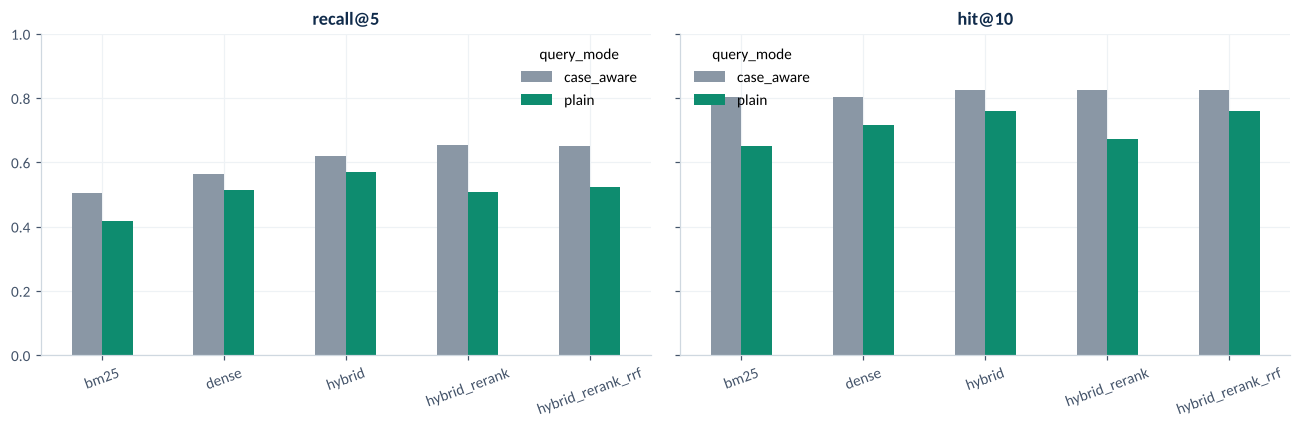

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
order = ["bm25", "dense", "hybrid", "hybrid_rerank", "hybrid_rerank_rrf"]
for ax, metric in zip(axes, ["recall@5", "hit@10"]):
    p = ret.pivot(index="method", columns="query_mode", values=metric).loc[order]
    p.plot.bar(ax=ax, color=[nbkit.GREY, nbkit.TEAL], rot=20); ax.set_title(metric); ax.set_xlabel(""); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

**Read-outs.**

* **Hybrid beats either alone.** Keywords catch exact terms like "Form 35"; embeddings catch paraphrase. Fusing them is
  cheap and robust.
* **Case-aware queries help** (the query is expanded with the case's loan scenario and missing documents). Recall@5 moves
  from about 0.57 to 0.62 for hybrid.
* **The reranker is not a clear win.** It helps when the query is case-aware (recall@5 0.65 vs 0.62 for plain hybrid)
  and hurts in plain mode (0.51 vs 0.57). Good example of "measure it, do not assume it". The fused ranker
  (`hybrid_rerank_rrf`) is the safest default because it never fell below plain hybrid on hit@10.
* With 46 queries, differences of a few points are within noise.

## 2. Does retrieval quality limit answer quality?

In [4]:
rag = pd.read_csv(config.RESULTS / "rag/week2_qwen3_8b/summary.csv").set_index("strategy")
cols = ["end_to_end_accuracy", "behavior_accuracy", "must_include_coverage", "citation_ok_rate", "retrieval_hit_rate", "cited_outside_context_rate"]
pd.concat([rag[cols], pd.read_csv(config.RESULTS / "baseline/week1_qwen3_8b/summary.csv").set_index("strategy").loc[["S1_FEW_SHOT"], ["end_to_end_accuracy", "behavior_accuracy", "must_include_coverage", "citation_ok_rate"]]]).round(3)

,end_to_end_accuracy,behavior_accuracy,must_include_coverage,citation_ok_rate,retrieval_hit_rate,cited_outside_context_rate
strategy,,,,,,
RAG_RETRIEVED,0.175,0.614,0.628,0.719,0.81,0.105
RAG_GOLD,0.175,0.596,0.625,0.860,1.00,0.018
S1_FEW_SHOT,0.246,0.649,0.606,0.825,NaN,NaN


Two surprising facts, both important:

1. **Perfect context (`RAG_GOLD`) scores the same end-to-end as retrieved context (17.5%).** Retrieval is *not* the
   bottleneck. Even when the right sources are in front of it, the model misses required facts.
2. **Citation quality improves with gold context** (72% to 86%), so retrieval does matter for *trust*, just not for
   the strict pass rate.

This is why Week 3 stopped treating the model as the only brain and moved date arithmetic, finding codes and form
paths into deterministic tools.

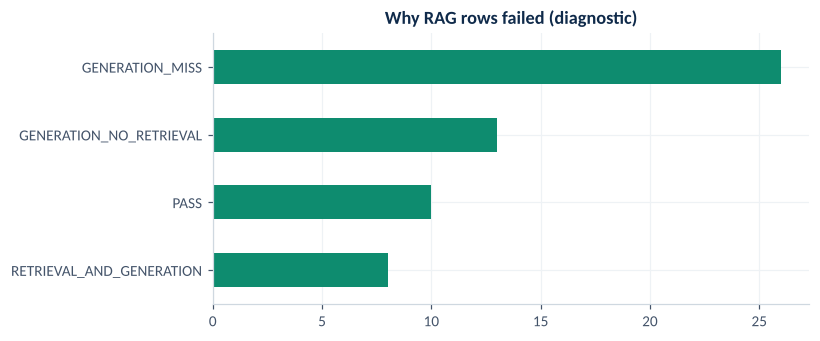

In [5]:
diag = pd.read_csv(config.RESULTS / "rag/week2_qwen3_8b/diagnostic.csv")
fig, ax = plt.subplots(figsize=(7, 3.2))
diag.cause.value_counts().sort_values().plot.barh(ax=ax, color=nbkit.TEAL)
ax.set_title("Why RAG rows failed (diagnostic)"); ax.set_ylabel(""); plt.show()

## 3. Live in this notebook: keyword search over the real corpus (no model needed)

This runs BM25 over the saved index so you can show how a question lands on sources.

In [6]:
from rank_bm25 import BM25Okapi
from rto_copilot.retrieval import tokenize
chunk_file = next((config.INDEX).glob("*.chunks.jsonl"))
chunks = nbkit.load_jsonl(chunk_file)
bm25 = BM25Okapi([tokenize(c["text"]) for c in chunks])
def keyword_search(q, k=5):
    scores = bm25.get_scores(tokenize(q)); top = np.argsort(scores)[::-1][:k]
    return pd.DataFrame([{"rank": i + 1, "source_id": chunks[j]["source_id"], "locator": chunks[j]["locator"], "score": round(float(scores[j]), 1),
                          "snippet": chunks[j]["text"][:110].replace("\n", " ")} for i, j in enumerate(top)])
print(f"{len(chunks):,} chunks loaded from {chunk_file.name}")
keyword_search("buyer deadline to apply for transfer of ownership Form 30 within days")

2,308 chunks loaded from w128_5ce5dffa218b5bd7.chunks.jsonl


,rank,source_id,locator,score,snippet
0,1,SRC-WB-FAQ,Hpa & Hpter Q3,27.7,West Bengal Transport FAQ (Hpa & Hpter): 11. What process are to be carried out for tr...
1,2,SRC-PARIVAHAN-TO,full page,26.8,Parivahan - Transfer of Ownership. set of forms given below under Form I in the case o...
2,3,SRC-PARIVAHAN-TO,full page,26.6,Parivahan - Transfer of Ownership. on auction. Guidelines Transfer of ownership in cas...
3,4,SRC-PARIVAHAN-TO,full page,25.0,Parivahan - Transfer of Ownership. period of three months to the registering authority...
4,5,SRC-WB-FAQ,Registration Q9,24.9,West Bengal Transport FAQ (Registration): 9. How the transfer of ownership of a vehicl...


In [7]:
keyword_search("financier written consent hypothecation transfer of ownership")

,rank,source_id,locator,score,snippet
0,1,SRC-FORM30,full form,28.3,Form 30 - Application for intimation and transfer of ownership. in the case of motor v...
1,2,SRC-FORM30,full form,25.7,Form 30 - Application for intimation and transfer of ownership. registration Number fr...
2,3,SRC-FORM29,full form,19.9,Form 29 - Notice of transfer of ownership of a motor vehicle. or motor number in the c...
3,4,SRC-FORM30,full form,18.5,Form 30 - Application for intimation and transfer of ownership. Back Print esign Docum...
4,5,SRC-FORM29,full form,17.7,Form 29 - Notice of transfer of ownership of a motor vehicle. for any inaccuracy or su...


Notice that the Act's section 50 and the Parivahan guidance both surface for the deadline question. That is the
source of the **14 days vs 30 days conflict** the copilot must flag instead of silently picking one.

## 4. Live: full hybrid retrieval with embeddings (optional)

Needs `pip install -e .[rag]` (sentence-transformers) and the model weights. Reproduces the table in section 1.

In [8]:
import importlib.util
have = importlib.util.find_spec("sentence_transformers") is not None
print("sentence-transformers installed:", have)
if RUN_LIVE and have:
    import subprocess
    env = {**os.environ, "PYTHONPATH": str(ROOT / "src")}
    print(subprocess.run([sys.executable, "-m", "rto_copilot.retrieval"], capture_output=True, text=True, env=env, cwd=ROOT).stdout[-2500:])

sentence-transformers installed: False
